Note: you may need to restart the kernel to use updated packages.
                              company ticker    exchange  \
0  Canadian Natural Resources Limited    CNQ  NYSE / TSX   
1                       Enbridge Inc.    ENB  NYSE / TSX   

                                            business  price (usd)  \
0               Crude oil and natural-gas production        49.65   
1  Liquids and natural-gas pipelines / energy inf...        46.60   

  market cap (usd) shares outstanding    p/e  eps (usd)  \
0          103.56B              2.06B  12.60       3.64   
1          103.86B        2.23B-2.27B  24.76       1.88   

   forward dividend (usd) forward dividend yield  \
0                    1.76                  3.54%   
1                    2.80                  6.01%   

   tsx quarterly dividend (cad)     next earnings  
0                         0.625  November 5, 2026  
1                         0.970  November 6, 2026  
         price (usd)    p/e  eps (usd)  forward divide

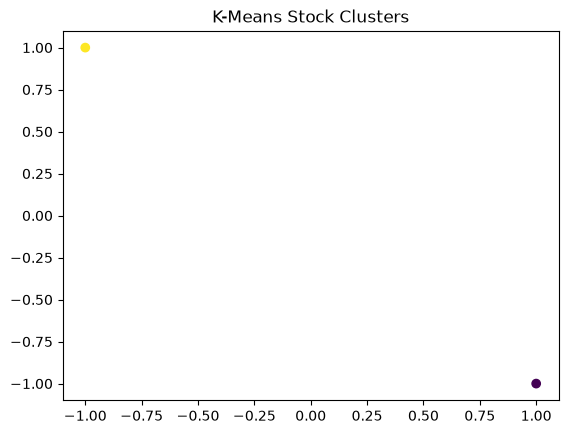

Important words: ['01' '103' '2026' '86b' 'canadian' 'cnq' 'crude' 'enb' 'energy' 'gas'
 'infrastructure' 'limited' 'liquids' 'natural' 'november' 'nyse' 'oil'
 'pipelines' 'production' 'tsx']
Analysis complete!


/var/folders/88/w4w1n8l12kd_z42_6mrnndmw0000gn/T/ipykernel_16445/874023146.py:37: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_cols = df.select_dtypes(include="object").columns.tolist()


In [1]:
# 1. Install libraries
%pip install -q pandas numpy matplotlib scikit-learn

# 2. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

# 3. Load dataset
df = pd.read_csv("CNQ_ENB_Stock_Shares.csv")
df.columns = df.columns.str.strip().str.lower()
print(df.head())

# 4. K-Means clustering on numerical data
num = df.select_dtypes(include=np.number).dropna(axis=1, how="all")
num = num.loc[:, num.nunique() > 1]
X = num.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median()).fillna(0)

if X.shape[1] > 0 and len(X) >= 2:
    X_scaled = StandardScaler().fit_transform(X)
    k = min(3, len(X))
    df["Cluster"] = KMeans(
        n_clusters=k, random_state=42, n_init=10
    ).fit_predict(X_scaled)
    print(df.groupby("Cluster")[X.columns.tolist()].mean())
    plt.scatter(X_scaled[:, 0], X_scaled[:, -1], c=df["Cluster"])
    plt.title("K-Means Stock Clusters")
    plt.show()
else:
    print("Insufficient numerical data for K-Means.")

# 5. NLP: find a text column automatically
text_cols = df.select_dtypes(include="object").columns.tolist()

if text_cols:
    text = df[text_cols].fillna("").astype(str).agg(" ".join, axis=1)
    tfidf = TfidfVectorizer(stop_words="english", max_features=20)
    matrix = tfidf.fit_transform(text)
    print("Important words:", tfidf.get_feature_names_out())
else:
    print("No text columns found; NLP requires headlines or descriptions.")

# 6. Save results
df.to_csv("CNQ_ENB_Analysis_Results.csv", index=False)
print("Analysis complete!")